<a href="https://colab.research.google.com/github/emf2229/Assignments/blob/main/ML_For_Climate_Assingnment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
!wget -nc "https://www.ncei.noaa.gov/data/oceans/archive/arc0196/0248762/1.1/data/0-data/tavg-1901_2000-monthly-normals-v1.0.nc"
!wget -nc "https://www.ncei.noaa.gov/data/oceans/archive/arc0196/0248762/1.1/data/0-data/prcp-1901_2000-monthly-normals-v1.0.nc"
!ls -la *.nc

File ‘tavg-1901_2000-monthly-normals-v1.0.nc’ already there; not retrieving.

File ‘prcp-1901_2000-monthly-normals-v1.0.nc’ already there; not retrieving.

-rw-r--r-- 1 root root 280673972 Feb 24  2022 prcp-1901_2000-monthly-normals-v1.0.nc
-rw-r--r-- 1 root root 280673988 Feb 24  2022 tavg-1901_2000-monthly-normals-v1.0.nc


In [22]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

In [24]:
ds_temp = xr.open_dataset("tavg-1901_2000-monthly-normals-v1.0.nc")
ds_prec = xr.open_dataset("prcp-1901_2000-monthly-normals-v1.0.nc")

print("temp vars:", list(ds_temp.data_vars))
print("prec vars:", list(ds_prec.data_vars))
print("dims:", ds_temp["mlytavg_norm"].dims)

temp vars: ['mlytavg_norm', 'mlytavg_std', 'mlytavg_min', 'mlytavg_max', 'mlytavg_flag', 'seastavg_norm', 'seastavg_std', 'seastavg_min', 'seastavg_max', 'seastavg_flag', 'anntavg_norm', 'anntavg_std', 'anntavg_min', 'anntavg_max', 'anntavg_flag']
prec vars: ['mlyprcp_norm', 'mlyprcp_std', 'mlyprcp_min', 'mlyprcp_max', 'mlyprcp_flag', 'seasprcp_norm', 'seasprcp_std', 'seasprcp_min', 'seasprcp_max', 'seasprcp_flag', 'annprcp_norm', 'annprcp_std', 'annprcp_min', 'annprcp_max', 'annprcp_flag']
dims: ('time', 'lat', 'lon')


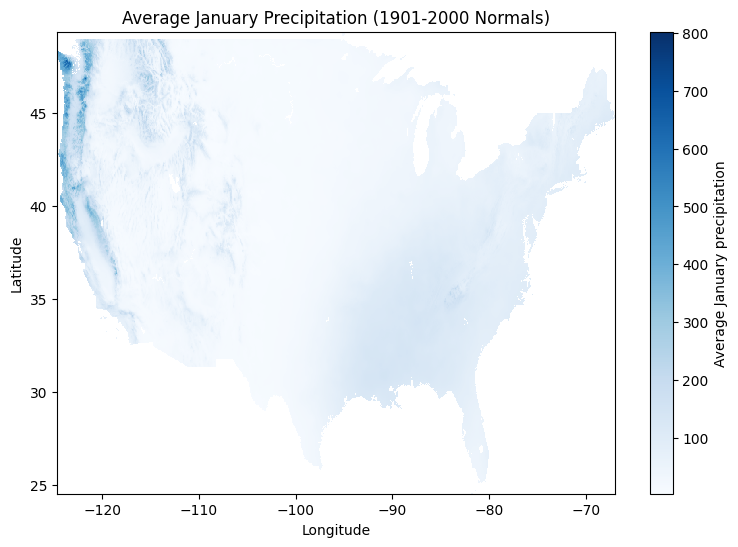

In [25]:
fig, ax = plt.subplots(figsize=(9, 6))
pcm = ax.pcolormesh(ds_prec["lon"], ds_prec["lat"],
                    ds_prec["mlyprcp_norm"].isel(time=0),
                    shading="auto", cmap="Blues")
fig.colorbar(pcm, ax=ax, label="Average January precipitation")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Average January Precipitation (1901-2000 Normals)")
plt.show()

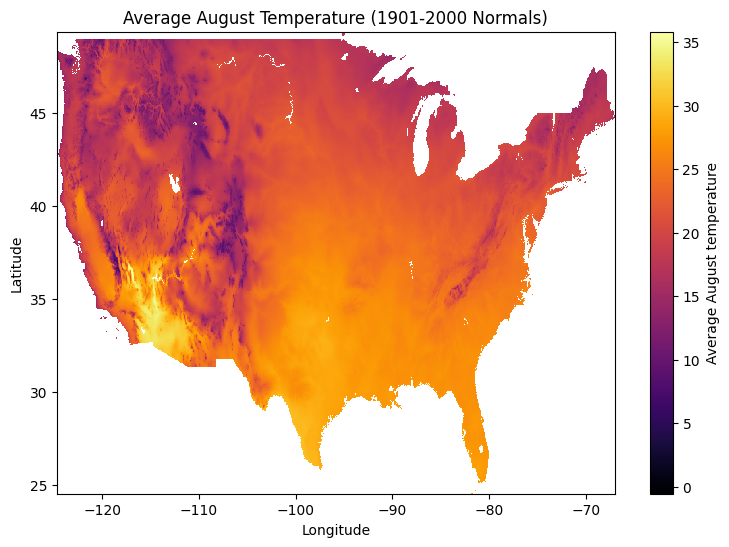

In [26]:
fig, ax = plt.subplots(figsize=(9, 6))
pcm = ax.pcolormesh(ds_temp["lon"], ds_temp["lat"],
                    ds_temp["mlytavg_norm"].isel(time=7),
                    shading="auto", cmap="inferno")
fig.colorbar(pcm, ax=ax, label="Average August temperature")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Average August Temperature (1901-2000 Normals)")
plt.show()

In [27]:
avgtemp = ds_temp["mlytavg_norm"].values
avgprec = ds_prec["mlyprcp_norm"].values

print("avgtemp:", avgtemp.shape)
print("avgprec:", avgprec.shape)

avgtemp: (12, 596, 1385)
avgprec: (12, 596, 1385)


In [28]:
lats = ds_temp["lat"].values
lons = ds_temp["lon"].values

lat_grid, lon_grid = np.meshgrid(lats, lons, indexing="ij")

print("lat_grid:", lat_grid.shape)
print("lon_grid:", lon_grid.shape)

lat_grid: (596, 1385)
lon_grid: (596, 1385)


In [29]:
mask = ~np.isnan(avgtemp[0])   # same shape as lat_grid (lat x lon)

print("mask shape:", mask.shape)
print("valid points:", mask.sum())

mask shape: (596, 1385)
valid points: 469758


In [30]:
avgtemp_masked = avgtemp[:, mask]
avgprec_masked = avgprec[:, mask]
lat_masked = lat_grid[mask]
lon_masked = lon_grid[mask]

print("NaNs left?", np.isnan(avgtemp_masked).any(), np.isnan(avgprec_masked).any())

NaNs left? False False


In [31]:
avgtemp_masked = avgtemp_masked.T
avgprec_masked = avgprec_masked.T

print("avgtemp_masked:", avgtemp_masked.shape)
print("avgprec_masked:", avgprec_masked.shape)

avgtemp_masked: (469758, 12)
avgprec_masked: (469758, 12)


In [32]:
temp_scaler = MinMaxScaler(feature_range=(-1, 1))
prec_scaler = MinMaxScaler(feature_range=(-1, 1))

avgtemp_scaled = temp_scaler.fit_transform(avgtemp_masked.reshape(-1, 1)).reshape(avgtemp_masked.shape)
avgprec_scaled = prec_scaler.fit_transform(avgprec_masked.reshape(-1, 1)).reshape(avgprec_masked.shape)

print("temp range:", avgtemp_scaled.min(), avgtemp_scaled.max())
print("prec range:", avgprec_scaled.min(), avgprec_scaled.max())

temp range: -1.0 0.9999999
prec range: -1.0 1.0


In [33]:
X = np.concatenate([avgtemp_scaled, avgprec_scaled], axis=1)

print("X:", X.shape)

X: (469758, 24)


In [34]:
kmeans8 = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans8_labels = kmeans8.fit_predict(X)

print("labels:", np.unique(kmeans8_labels))

labels: [0 1 2 3 4 5 6 7]


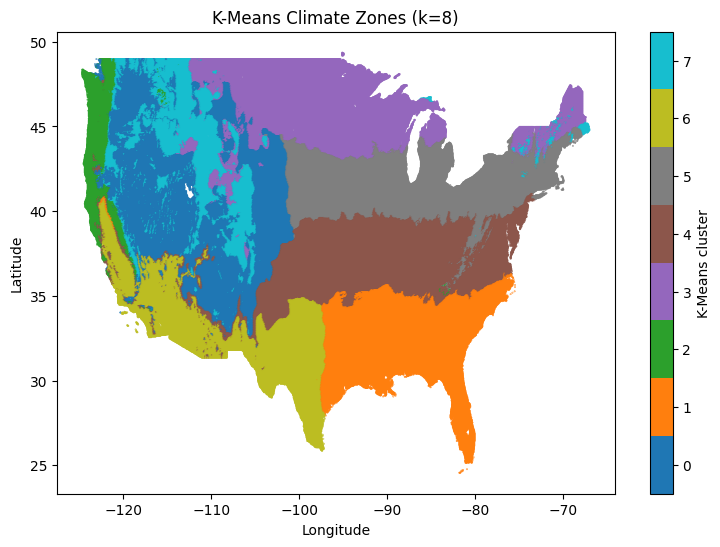

In [35]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(lon_masked, lat_masked, c=kmeans8_labels, s=0.1,
                cmap=plt.get_cmap("tab10", 8), vmin=-0.5, vmax=7.5)
fig.colorbar(sc, ax=ax, ticks=range(8), label="K-Means cluster")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("K-Means Climate Zones (k=8)")
plt.show()

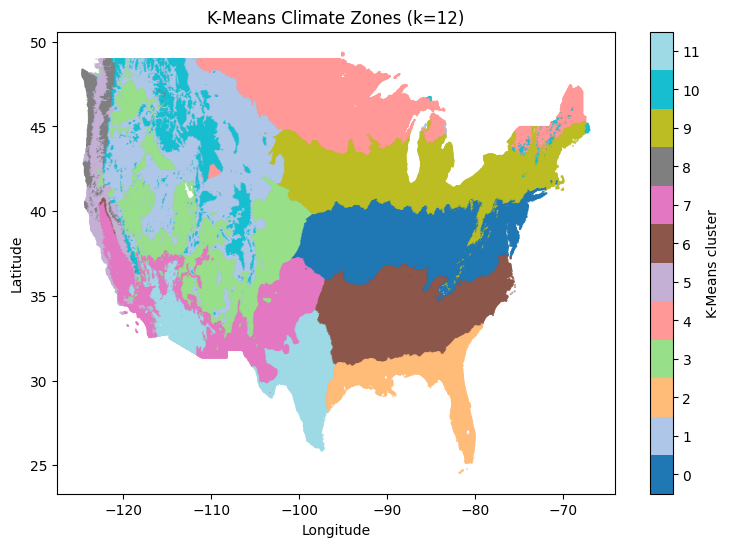

In [36]:
kmeans12 = KMeans(n_clusters=12, random_state=42, n_init=10)
kmeans12_labels = kmeans12.fit_predict(X)

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(lon_masked, lat_masked, c=kmeans12_labels, s=0.1,
                cmap=plt.get_cmap("tab20", 12), vmin=-0.5, vmax=11.5)
fig.colorbar(sc, ax=ax, ticks=range(12), label="K-Means cluster")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("K-Means Climate Zones (k=12)")
plt.show()

In [37]:
gmm = GaussianMixture(n_components=8, random_state=42)
gmm_labels = gmm.fit_predict(X)

print("components:", np.unique(gmm_labels))

components: [0 1 2 3 4 5 6 7]


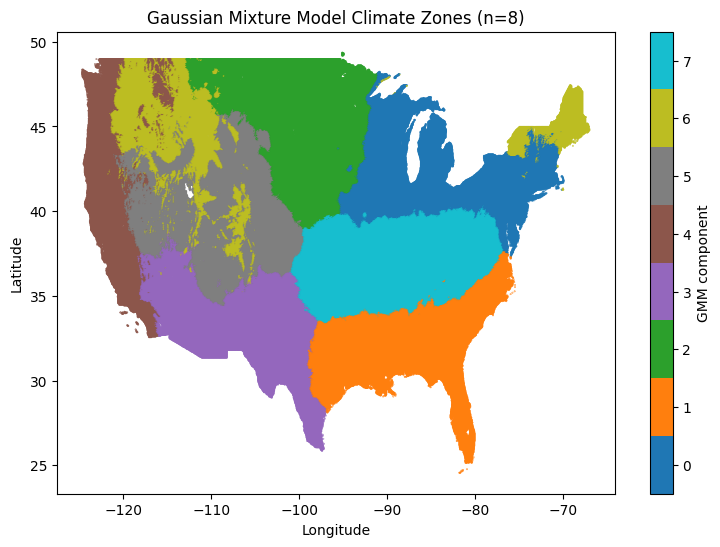

In [38]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(lon_masked, lat_masked, c=gmm_labels, s=0.1,
                cmap=plt.get_cmap("tab10", 8), vmin=-0.5, vmax=7.5)
fig.colorbar(sc, ax=ax, ticks=range(8), label="GMM component")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Gaussian Mixture Model Climate Zones (n=8)")
plt.show()